## Modeling Approach & Results

**Question:** Do multivariate sensor histories predict remaining useful life (RUL) well enough to (1) estimate cycles remaining and (2) raise a maintenance alert before an engine is within 30 cycles of failure? In aviation, a missed alert is a safety risk first, so alert **recall** is treated as the constraint.

**Data scope:** NASA CMAPSS **FD001** only. Train = 100 run-to-failure engines (20,631 rows). Test = 100 truncated engines (13,096 rows), labeled from `RUL_FD001.txt`. Engine identity = (`split`, `unit_id`). Every model choice (Ridge α, alert thresholds, LSTM early stopping) was made on **training engines only**; the test set was scored once.

**Models:** Ridge regression on 39 features (current + 30-cycle rolling mean/std, standardized), α chosen by 5-fold CV **grouped by engine**. LSTM (64→32→16→1, dropout 0.2) on 30-cycle windows of the 13 normalized sensors, early-stopped on 20 held-out training engines, 3 seeds.

**Results (FD001 test set; LSTM = mean ± sd over 3 seeds)**

| Metric | Ridge | LSTM |
|---|---|---|
| Last-cycle RMSE, standard protocol (n = 100 engines) | 17.51 | **13.05 ± 0.33** |
| PHM08 score (lower is better) | 664 | **308 ± 7** |
| RMSE on aligned test rows (10,196) | 19.82 | **14.88 ± 1.09** |
| Train RMSE | 18.98 | 13.50 ± 0.93 |
| Alert row recall / precision (τ tuned for 90% recall on non-test engines) | 0.75 / 0.73 | 0.76 / 0.84 |
| Engines alerted of 25 in window / false alarms of 75 | 21 / 1 | 21–24 / 1–2 |

**Significance (engine = unit of analysis, not row):** the LSTM has lower per-engine RMSE on 67–85 of 100 engines (Wilcoxon p < 0.0001 for every seed). Engine-bootstrap RMSE gap: 3.9–6.1 cycles, and every 95% CI excludes zero.

**Alert layer:** thresholds tuned for 90% recall on training engines reached 75–81% row recall on test. Test engines are truncated, so 63% of test positives sit at RUL 21–30, right at the alert boundary, vs. 32% in training. A dedicated logistic classifier was competitive (row F1 0.82, 25/25 engines, 1 false alarm; average precision 0.91 vs. 0.83 for Ridge).

**Decision:** LSTM (seed 1, chosen by lowest **validation** RMSE) is the RUL champion candidate. Ridge is kept as the interpretable baseline. Its SHAP importance, grouped by sensor because `sensor_8_roll_mean` and `sensor_13_roll_mean` correlate at r = 0.987: sensor 8 > 4 > 13 > 11 > 12.

In [0]:
# ============================================================
# CELL 0 — Evaluation utilities (rul_eval)
# Engine = (split, unit_id). d = predicted - true; d > 0 = LATE (dangerous).
# Alert rule: alert when predicted RUL <= tau. Label: true RUL <= 30.
# tau is chosen on training engines (out-of-fold), never on test.
# ============================================================

import numpy as np
import pandas as pd
from scipy import stats
from sklearn.model_selection import GroupKFold

ALERT_HORIZON = 30   # label: true RUL <= 30 cycles
RUL_CAP = 125


# ---------------- Regression metrics ----------------
def rmse(y_true, y_pred) -> float:
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    return float(np.sqrt(np.mean((y_pred - y_true) ** 2)))


def phm08_score(y_true, y_pred) -> float:
    """PHM08 challenge score (Saxena et al., 2008). Lower is better. Late predictions
    (d > 0) are penalized more: sum(exp(-d/13)-1) for d<0, sum(exp(d/10)-1) for d>=0."""
    d = np.asarray(y_pred, float) - np.asarray(y_true, float)
    return float(np.sum(np.where(d < 0, np.exp(-d / 13.0) - 1, np.exp(d / 10.0) - 1)))


def last_cycle(df, engine_cols=("unit_id",), time_col="time_cycles"):
    """One row per engine: its final observed cycle (the standard CMAPSS test point)."""
    return (df.sort_values(list(engine_cols) + [time_col])
              .groupby(list(engine_cols), as_index=False).tail(1))


def standard_cmapss_metrics(test_df, pred_col, true_col="RUL", cap=RUL_CAP) -> dict:
    """Score only each test engine's last cycle against RUL_FD00x.txt.
    true_col must be the UNCAPPED true RUL."""
    last = last_cycle(test_df)
    y = last[true_col].to_numpy(float)
    p = last[pred_col].to_numpy(float)
    return {
        "n_engines": int(len(last)),
        "last_cycle_rmse_vs_capped_truth": rmse(np.minimum(y, cap), p),
        "last_cycle_rmse_vs_raw_truth": rmse(y, p),
        "last_cycle_mae_vs_capped_truth": float(np.mean(np.abs(np.minimum(y, cap) - p))),
        "phm08_score_vs_raw_truth": phm08_score(y, p),
        "phm08_score_vs_capped_truth": phm08_score(np.minimum(y, cap), p),
    }


# ---------------- Out-of-fold predictions (for threshold tuning) ----------------
def oof_predict(make_model, X, y, groups, n_splits=5, clip=(0, RUL_CAP), method="predict"):
    """Out-of-fold predictions with folds split BY ENGINE (GroupKFold)."""
    oof = np.full(len(y), np.nan)
    for fit_idx, val_idx in GroupKFold(n_splits=n_splits).split(X, y, groups):
        m = make_model().fit(X.iloc[fit_idx], y.iloc[fit_idx])
        out = getattr(m, method)(X.iloc[val_idx])
        if method == "predict_proba":
            out = out[:, 1]
        oof[val_idx] = out
    if clip is not None and method == "predict":
        oof = np.clip(oof, *clip)
    return oof


# ---------------- Alert threshold tuning ----------------
def alert_counts(y_true_rul, score, tau, horizon=ALERT_HORIZON, higher_is_alert=False) -> dict:
    y = np.asarray(y_true_rul) <= horizon
    s = np.asarray(score)
    a = s >= tau if higher_is_alert else s <= tau
    tp, fp = int(np.sum(a & y)), int(np.sum(a & ~y))
    fn, tn = int(np.sum(~a & y)), int(np.sum(~a & ~y))
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return dict(tau=float(tau), tp=tp, fp=fp, fn=fn, tn=tn,
                precision=prec, recall=rec, f1=f1)


def threshold_curve(y_true_rul, score, horizon=ALERT_HORIZON, higher_is_alert=False, taus=None):
    """Precision/recall/F1 at every candidate threshold."""
    if taus is None:
        taus = np.unique(np.round(np.asarray(score, float), 2))
    return pd.DataFrame([alert_counts(y_true_rul, score, t, horizon, higher_is_alert)
                         for t in taus])


def choose_threshold(y_true_rul, score, recall_target=0.90, horizon=ALERT_HORIZON,
                     higher_is_alert=False) -> dict:
    """Best-precision threshold that still meets the recall target.
    Call on OUT-OF-FOLD / validation predictions, then apply to test once."""
    curve = threshold_curve(y_true_rul, score, horizon, higher_is_alert)
    ok = curve[curve.recall >= recall_target]
    if ok.empty:
        raise ValueError(f"No threshold reaches recall {recall_target}")
    return ok.loc[ok.precision.idxmax()].to_dict()


def wilson_ci(k, n, z=1.96):
    """95% Wilson interval for a proportion (small counts)."""
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    den = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return (float(c - h), float(c + h))


def engine_level_alerts(test_df, score_col, tau, true_col="RUL", horizon=ALERT_HORIZON,
                        higher_is_alert=False) -> dict:
    """One decision per engine at its LAST cycle: alerted engines truly within the horizon,
    and false alarms on healthy engines. Independent counts (row counts are not)."""
    last = last_cycle(test_df)
    c = alert_counts(last[true_col], last[score_col], tau, horizon, higher_is_alert)
    c["recall_ci95"] = wilson_ci(c["tp"], c["tp"] + c["fn"])
    c["precision_ci95"] = wilson_ci(c["tp"], c["tp"] + c["fp"])
    return c


# ---------------- Model comparison: ENGINE is the unit of analysis ----------------
def per_engine_errors(df, true_col, pred_a, pred_b, engine_cols=("unit_id",)):
    sq = df.assign(_ea=(df[pred_a] - df[true_col]) ** 2, _eb=(df[pred_b] - df[true_col]) ** 2)
    g = sq.groupby(list(engine_cols))
    return pd.DataFrame({"rmse_a": np.sqrt(g["_ea"].mean()),
                         "rmse_b": np.sqrt(g["_eb"].mean()),
                         "n_rows": g.size()})


def compare_models(df, true_col, pred_a, pred_b, n_boot=10_000, seed=0, engine_cols=("unit_id",)) -> dict:
    """A vs B on ALIGNED rows: per-engine RMSE (Wilcoxon + paired t, n = engines),
    last-cycle abs error (Wilcoxon), and a bootstrap that resamples ENGINES.
    pooled_rmse_diff = A - B; negative means A is better."""
    df = df.dropna(subset=[pred_a, pred_b])
    pe = per_engine_errors(df, true_col, pred_a, pred_b, engine_cols)
    diff = pe.rmse_a - pe.rmse_b
    w = stats.wilcoxon(pe.rmse_a, pe.rmse_b)
    t = stats.ttest_rel(pe.rmse_a, pe.rmse_b)

    last = last_cycle(df, engine_cols)
    wl = stats.wilcoxon((last[pred_a] - last[true_col]).abs(),
                        (last[pred_b] - last[true_col]).abs())

    sq = df.assign(ea=(df[pred_a] - df[true_col]) ** 2, eb=(df[pred_b] - df[true_col]) ** 2)
    agg = sq.groupby(list(engine_cols)).agg(sa=("ea", "sum"), sb=("eb", "sum"), n=("ea", "size"))
    sa, sb, n = agg.sa.to_numpy(), agg.sb.to_numpy(), agg.n.to_numpy()
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(agg), size=(n_boot, len(agg)))
    boot = np.sqrt(sa[idx].sum(1) / n[idx].sum(1)) - np.sqrt(sb[idx].sum(1) / n[idx].sum(1))
    point = np.sqrt(sa.sum() / n.sum()) - np.sqrt(sb.sum() / n.sum())

    return {
        "n_engines": int(len(pe)),
        "a_better_on_n_engines": int((diff < 0).sum()),
        "per_engine_rmse_median_diff": float(diff.median()),
        "wilcoxon_per_engine_rmse_p": float(w.pvalue),
        "paired_t_per_engine_rmse_t": float(t.statistic),
        "paired_t_per_engine_rmse_p": float(t.pvalue),
        "wilcoxon_last_cycle_abs_err_p": float(wl.pvalue),
        "pooled_rmse_diff": float(point),
        "pooled_rmse_diff_ci95": (float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5))),
    }


def align_predictions(base, other, col, keys=("unit_id", "time_cycles")):
    """Join another model's predictions onto base by engine AND cycle — never by row
    position. Rows the other model can't score (LSTM warm-up) become NaN."""
    return base.merge(other[list(keys) + [col]], on=list(keys), how="left", validate="1:1")


print("✅ Evaluation utilities loaded")

✅ Evaluation utilities loaded


In [0]:
# ============================================================
# CELL 1 — Modeling Setup: Load Silver, Prepare Train/Test
# Notebook: 04_modeling
# Engine = (split, unit_id); rows sorted by engine and cycle so every
# per-engine operation (CV folds, last-cycle scoring) is well defined.
# ============================================================

import mlflow
import mlflow.sklearn
import pandas as pd
import numpy as np

EXPERIMENT_PATH = "/Users/gkolthoff1@live.maryville.edu/rul_prediction_cmapss"

silver_fd001 = spark.table("workspace.predictive_maintenance.silver_fd001")

train_df = (silver_fd001.filter("split = 'train'").toPandas()
            .sort_values(["unit_id", "time_cycles"]).reset_index(drop=True))
test_df  = (silver_fd001.filter("split = 'test'").toPandas()
            .sort_values(["unit_id", "time_cycles"]).reset_index(drop=True))

SENSORS = [2, 3, 4, 7, 8, 9, 11, 12, 13, 15, 17, 20, 21]
feature_cols = (
    [f"sensor_{s}_norm" for s in SENSORS] +
    [f"sensor_{s}_roll_mean" for s in SENSORS] +
    [f"sensor_{s}_roll_std" for s in SENSORS]
)
target = "RUL_capped"

X_train = train_df[feature_cols].fillna(0)
y_train = train_df[target]
X_test  = test_df[feature_cols].fillna(0)
y_test  = test_df[target]
groups  = train_df["unit_id"]          # CV folds split BY ENGINE, never by row

print(f"Training set: {X_train.shape}  ({train_df.unit_id.nunique()} engines)")
print(f"Test set:     {X_test.shape}  ({test_df.unit_id.nunique()} engines)")
print(f"Features:     {len(feature_cols)}")
print(f"Target range: [{y_train.min():.0f}, {y_train.max():.0f}]")
print(f"Test alert positives (true RUL <= 30): {(test_df['RUL'] <= 30).sum()}")

{"ts": "2026-10-13 00:52:47.864", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chpub3RlYm9va3MvMzAyMTk5NTIyMTMwNjc2MxABIAEyJDAxYTEzMmJmLTAxNjktNzljMC05YTM2LThkOTE2MzFhNjAzNTokOTVkYzA0ZjYtZTI3NS0zMjFiLWEwOWYtZmE1YTExNzk2MmIwSgwIxIG21gYQwIiHzgNQAVgBYAFosLmLqOrEow2IAQA=.", "context": {}}
{"ts": "2026-10-13 00:52:47.864", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chpub3RlYm9va3MvMzAyMTk5NTIyMTMwNjc2MxABIAEyJDAxYTEzMmJmLTAxNjktNzljMC05YTM2LThkOTE2MzFhNjAzNTokOTVkYzA0ZjYtZTI3NS0zMjFiLWEwOWYtZmE1YTExNzk2MmIwSgwIxIG21gYQwIiHzgNQAVgBYAFosLmLqOrEow2IAQA=.", "context": {}}
{"ts": "2026-10-13 00:52:47.864", "level": "WARNING", "logger": "pyspark.sql.connect.logging", "msg": "Effective usage policy for this session is cct.Chpub3RlYm9va3MvMzAyMTk5NTIyMTMwNjc2MxABIAEyJDAxYTEzMmJmLTAxNjktNzljMC05YTM2LThkOTE2MzFhNjAzNTokOTVkYzA0ZjYtZTI3NS0zMjFiLWEwOWYtZmE1YTEx

Training set: (20631, 39)  (100 engines)
Test set:     (13096, 39)  (100 engines)
Features:     39
Target range: [0, 125]
Test alert positives (true RUL <= 30): 332


In [0]:
# ============================================================
# CELL 2 — Model 1: Ridge Regression (interpretable baseline)
# - Features standardized inside the pipeline (roll_mean/roll_std are on
#   raw sensor scale, so L2 would otherwise penalize features unevenly)
# - alpha chosen by 5-fold CV grouped BY ENGINE (GroupKFold)
# - Alert threshold tau chosen on OUT-OF-FOLD training predictions to hit
#   90% recall, then frozen and applied to test once
# ============================================================

from sklearn.linear_model import Ridge, RidgeCV
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

mlflow.set_experiment(EXPERIMENT_PATH)

ALPHAS = [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0]
RECALL_TARGET = 0.90

cv_splits = list(GroupKFold(n_splits=5).split(X_train, y_train, groups))
alpha = RidgeCV(alphas=ALPHAS, cv=cv_splits).fit(
    StandardScaler().fit_transform(X_train), y_train).alpha_
make_ridge = lambda: make_pipeline(StandardScaler(), Ridge(alpha=alpha))

with mlflow.start_run(run_name="ridge_v2_engine_cv"):

    ridge_model_obj = make_ridge().fit(X_train, y_train)
    test_df["ridge_pred"] = np.clip(ridge_model_obj.predict(X_test), 0, 125)
    train_rmse = rmse(y_train, np.clip(ridge_model_obj.predict(X_train), 0, 125))

    # Standard CMAPSS protocol: last cycle of each test engine vs RUL_FD001.txt
    ridge_std = standard_cmapss_metrics(test_df, "ridge_pred", true_col="RUL")
    all_cycle_rmse = rmse(test_df["RUL_capped"], test_df["ridge_pred"])
    all_cycle_mae  = float(np.mean(np.abs(test_df["RUL_capped"] - test_df["ridge_pred"])))

    # Alert threshold from out-of-fold TRAINING predictions (never test)
    oof_ridge = oof_predict(make_ridge, X_train, y_train, groups)
    TAU_RIDGE = choose_threshold(y_train, oof_ridge, recall_target=RECALL_TARGET)["tau"]
    ridge_rows = alert_counts(test_df["RUL"], test_df["ridge_pred"], TAU_RIDGE)
    ridge_eng  = engine_level_alerts(test_df, "ridge_pred", TAU_RIDGE)

    mlflow.log_param("model_type", "RidgeCV")
    mlflow.log_param("pipeline", "StandardScaler -> Ridge")
    mlflow.log_param("alphas_searched", str(ALPHAS))
    mlflow.log_param("best_alpha", alpha)
    mlflow.log_param("cv", "GroupKFold(5) by engine")
    mlflow.log_param("features", len(feature_cols))
    mlflow.log_param("rul_cap", 125)
    mlflow.log_param("rolling_window", 30)
    mlflow.log_param("subset", "FD001")
    mlflow.log_param("alert_tau", round(TAU_RIDGE, 2))
    mlflow.log_param("alert_tau_source", f"OOF train, recall>={RECALL_TARGET}")

    mlflow.log_metric("train_rmse", train_rmse)
    mlflow.log_metric("test_rmse", all_cycle_rmse)
    mlflow.log_metric("test_mae", all_cycle_mae)
    mlflow.log_metric("last_cycle_rmse", ridge_std["last_cycle_rmse_vs_capped_truth"])
    mlflow.log_metric("last_cycle_rmse_raw", ridge_std["last_cycle_rmse_vs_raw_truth"])
    mlflow.log_metric("phm08_score", ridge_std["phm08_score_vs_raw_truth"])
    mlflow.log_metric("alert_recall_rows", ridge_rows["recall"])
    mlflow.log_metric("alert_precision_rows", ridge_rows["precision"])
    mlflow.log_metric("alert_f1_rows", ridge_rows["f1"])

    mlflow.sklearn.log_model(ridge_model_obj, artifact_path="ridge_model",
                             input_example=X_train.head(5))

print("=== RIDGE REGRESSION RESULTS (FD001) ===")
print(f"Best alpha (GroupKFold CV):  {alpha}")
print(f"Train RMSE:                  {train_rmse:.2f}")
print(f"Last-cycle RMSE (n=100):     {ridge_std['last_cycle_rmse_vs_capped_truth']:.2f}"
      f"  (raw truth {ridge_std['last_cycle_rmse_vs_raw_truth']:.2f})")
print(f"PHM08 score:                 {ridge_std['phm08_score_vs_raw_truth']:.0f}")
print(f"All-cycle test RMSE / MAE:   {all_cycle_rmse:.2f} / {all_cycle_mae:.2f}")
print(f"Alert tau (OOF, recall>={RECALL_TARGET}): {TAU_RIDGE:.1f}")
print(f"Test rows:   recall {ridge_rows['recall']:.3f} ({ridge_rows['tp']}/{ridge_rows['tp']+ridge_rows['fn']})"
      f" | precision {ridge_rows['precision']:.3f} | F1 {ridge_rows['f1']:.3f}")
print(f"Test engines at last cycle: {ridge_eng['tp']}/{ridge_eng['tp']+ridge_eng['fn']} alerted,"
      f" {ridge_eng['fp']} false alarms of {ridge_eng['fp']+ridge_eng['tn']}")

2026/10/13 00:53:06 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
🔗 View Logged Model at: https://dbc-875e7f65-c010.cloud.databricks.com/ml/experiments/3021995221306764/models/m-9484760d9d9d429983fb9b051d7f5754?o=7474646022806704


=== RIDGE REGRESSION RESULTS (FD001) ===
Best alpha (GroupKFold CV):  100.0
Train RMSE:                  18.98
Last-cycle RMSE (n=100):     17.51  (raw truth 18.83)
PHM08 score:                 664
All-cycle test RMSE / MAE:   18.80 / 14.09
Alert tau (OOF, recall>=0.9): 50.3
Test rows:   recall 0.747 (248/332) | precision 0.732 | F1 0.739
Test engines at last cycle: 21/25 alerted, 1 false alarms of 75


In [0]:
%pip install torch

Looking in indexes: [REDACTED]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 454.0/454.0 MB 134.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 651.0/651.0 MB 76.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 221.1/221.1 MB 103.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 106.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.2/60.2 MB 99.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 542.8/542.8 MB 77.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 89.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.0/43.0 MB 96.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 61.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.1/214.1 MB 88.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 40.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 MB 87.5 MB/s eta 0:00:00
   ━━━━━━━━━━

In [0]:
import torch
print(torch.__version__)

/local_disk0/.ephemeral_nfs/envs/pythonEnv-0ce29129-aa25-4bff-9067-9fb8e3dec245/lib/python3.12/site-packages/torch/_vmap_internals.py:9: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  from torch.utils._pytree import _broadcast_to_and_flatten, tree_flatten, tree_unflatten


2.14.1+cu130


In [0]:
# ============================================================
# CELL 3 — Model 2: LSTM (PyTorch) — corrected training + evaluation
# Same architecture as before (LSTM 64 -> LSTM 32 -> Dense 16 -> 1, dropout 0.2).
# Fixes vs. the first version:
#  1. Window INCLUDES the current cycle: X[i-29 : i+1] predicts y[i]
#  2. Early stopping on 20 HELD-OUT TRAINING ENGINES (validation loss),
#     not on training loss
#  3. Target scaled to [0,1] (RUL/125) for stable optimization
#  4. Predictions keyed by (unit_id, time_cycles) so they join to Ridge
#     by engine and cycle, never by row position
#  5. 3 seeds, reported as mean +/- sd
#  6. Alert threshold chosen on the held-out validation engines (not test)
# Runtime: roughly 2-5 minutes per seed on CPU.
# ============================================================

import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import mlflow
import mlflow.pytorch

SEQ_LEN = 30
CAP = 125.0
SEEDS = (0, 1, 2)
MAX_EPOCHS = 100
PATIENCE = 10


def build_sequences(df, feat_cols, target_col="RUL_capped", seq_len=SEQ_LEN,
                    engine_col="unit_id", time_col="time_cycles"):
    """Windows ending AT cycle i (inclusive). Returns X, y, and the
    (unit_id, time_cycles) key of each window."""
    Xs, ys, keys = [], [], []
    for uid, eng in df.sort_values([engine_col, time_col]).groupby(engine_col, sort=True):
        X = eng[feat_cols].to_numpy(np.float32)
        y = eng[target_col].to_numpy(np.float32)
        t = eng[time_col].to_numpy()
        for i in range(seq_len - 1, len(eng)):
            Xs.append(X[i - seq_len + 1: i + 1])
            ys.append(y[i])
            keys.append((uid, t[i]))
    return (np.stack(Xs), np.asarray(ys, np.float32),
            pd.DataFrame(keys, columns=[engine_col, time_col]))


class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden1=64, hidden2=32):
        super().__init__()
        self.lstm1 = nn.LSTM(input_size, hidden1, batch_first=True)
        self.drop1 = nn.Dropout(0.2)
        self.lstm2 = nn.LSTM(hidden1, hidden2, batch_first=True)
        self.drop2 = nn.Dropout(0.2)
        self.fc1 = nn.Linear(hidden2, 16)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(16, 1)

    def forward(self, x):
        x, _ = self.lstm1(x)
        x = self.drop1(x)
        x, _ = self.lstm2(x)
        x = self.drop2(x[:, -1, :])
        return self.fc2(self.relu(self.fc1(x)))


def predict(model, X, batch=2048):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(X), batch):
            out.append(model(torch.from_numpy(X[i:i + batch])).numpy().ravel())
    return np.clip(np.concatenate(out) * CAP, 0, CAP)


def train_lstm(train_df, feat_cols, val_frac=0.2, seed=0, max_epochs=MAX_EPOCHS,
               patience=PATIENCE, lr=1e-3, batch_size=64, verbose=True):
    """Hold out val_frac of TRAINING ENGINES for early stopping."""
    torch.manual_seed(seed)
    np.random.seed(seed)
    units = np.array(sorted(train_df.unit_id.unique()))
    rng = np.random.default_rng(seed)
    val_units = rng.choice(units, size=int(round(len(units) * val_frac)), replace=False)
    fit_df = train_df[~train_df.unit_id.isin(val_units)]
    val_df = train_df[train_df.unit_id.isin(val_units)]

    Xf, yf, _ = build_sequences(fit_df, feat_cols)
    Xv, yv, _ = build_sequences(val_df, feat_cols)
    loader = DataLoader(TensorDataset(torch.from_numpy(Xf), torch.from_numpy(yf / CAP).unsqueeze(1)),
                        batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))

    model = LSTMModel(Xf.shape[2])
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=4)
    loss_fn = nn.MSELoss()
    best, best_state, bad, hist = np.inf, None, 0, []

    for epoch in range(max_epochs):
        model.train()
        for xb, yb in loader:
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        val_rmse = float(np.sqrt(np.mean((predict(model, Xv) - yv) ** 2)))
        sched.step(val_rmse)
        hist.append(val_rmse)
        if val_rmse < best - 1e-3:
            best, best_state, bad = val_rmse, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                break
        if verbose and (epoch + 1) % 5 == 0:
            print(f"  seed {seed} epoch {epoch + 1}: val RMSE {val_rmse:.2f} (best {best:.2f})")

    model.load_state_dict(best_state)
    return model, {"best_val_rmse": best, "epochs_run": epoch + 1,
                   "best_epoch": int(np.argmin(hist)) + 1,
                   "val_units": sorted(int(u) for u in val_units)}


def lstm_test_predictions(model, df, feat_cols, col="lstm_pred"):
    """Predictions for every window, keyed by (unit_id, time_cycles)."""
    X, _, keys = build_sequences(df, feat_cols)
    keys[col] = predict(model, X)
    return keys


# ------------------------------------------------------------
# Train + evaluate, one MLflow run per seed
# ------------------------------------------------------------
norm_cols = [c for c in feature_cols if c.endswith("_norm")]
mlflow.set_experiment(EXPERIMENT_PATH)
lstm_runs = {}

for seed in SEEDS:
    print(f"\n--- LSTM seed {seed} ---")
    with mlflow.start_run(run_name=f"lstm_v2_seed{seed}"):
        model, hist = train_lstm(train_df, norm_cols, seed=seed)

        Xtr, ytr, _ = build_sequences(train_df, norm_cols)
        train_rmse_lstm = rmse(ytr, predict(model, Xtr))

        preds = lstm_test_predictions(model, test_df, norm_cols)
        aligned = align_predictions(test_df, preds, "lstm_pred").dropna(subset=["lstm_pred"])
        std = standard_cmapss_metrics(aligned, "lstm_pred", true_col="RUL")
        aligned_rmse = rmse(aligned["RUL_capped"], aligned["lstm_pred"])
        aligned_mae = float(np.mean(np.abs(aligned["RUL_capped"] - aligned["lstm_pred"])))

        # Alert threshold from this seed's held-out VALIDATION engines (not test)
        vdf = train_df[train_df.unit_id.isin(hist["val_units"])]
        Xv, yv, _ = build_sequences(vdf, norm_cols)
        tau = choose_threshold(yv, predict(model, Xv), recall_target=RECALL_TARGET)["tau"]
        rows = alert_counts(aligned["RUL"], aligned["lstm_pred"], tau)
        eng = engine_level_alerts(aligned, "lstm_pred", tau)

        mlflow.log_param("model_type", "LSTM_PyTorch_v2")
        mlflow.log_param("seed", seed)
        mlflow.log_param("architecture", "LSTM64-LSTM32-Dense16-1, dropout 0.2")
        mlflow.log_param("sequence_length", SEQ_LEN)
        mlflow.log_param("features", len(norm_cols))
        mlflow.log_param("target_scaling", "RUL_capped / 125")
        mlflow.log_param("early_stopping", f"val RMSE on 20 held-out train engines, patience {PATIENCE}")
        mlflow.log_param("best_epoch", hist["best_epoch"])
        mlflow.log_param("epochs_run", hist["epochs_run"])
        mlflow.log_param("alert_tau", round(tau, 2))
        mlflow.log_param("alert_tau_source", f"held-out val engines, recall>={RECALL_TARGET}")

        mlflow.log_metric("train_rmse", train_rmse_lstm)
        mlflow.log_metric("val_rmse", hist["best_val_rmse"])
        mlflow.log_metric("test_rmse", aligned_rmse)
        mlflow.log_metric("test_mae", aligned_mae)
        mlflow.log_metric("last_cycle_rmse", std["last_cycle_rmse_vs_capped_truth"])
        mlflow.log_metric("last_cycle_rmse_raw", std["last_cycle_rmse_vs_raw_truth"])
        mlflow.log_metric("phm08_score", std["phm08_score_vs_raw_truth"])
        mlflow.log_metric("alert_recall_rows", rows["recall"])
        mlflow.log_metric("alert_precision_rows", rows["precision"])
        mlflow.log_metric("alert_f1_rows", rows["f1"])
        mlflow.pytorch.log_model(model, artifact_path="lstm_model")

    lstm_runs[seed] = dict(model=model, hist=hist, preds=preds, std=std, tau=tau,
                           rows=rows, eng=eng, train_rmse=train_rmse_lstm,
                           aligned_rmse=aligned_rmse, aligned_mae=aligned_mae)
    print(f"seed {seed}: best epoch {hist['best_epoch']}/{hist['epochs_run']} | "
          f"train {train_rmse_lstm:.2f} | val {hist['best_val_rmse']:.2f} | "
          f"last-cycle {std['last_cycle_rmse_vs_capped_truth']:.2f} | "
          f"PHM08 {std['phm08_score_vs_raw_truth']:.0f} | "
          f"tau {tau:.1f}: rows recall {rows['recall']:.3f} precision {rows['precision']:.3f} | "
          f"engines {eng['tp']}/{eng['tp']+eng['fn']}, {eng['fp']} false alarms")

# ------------------------------------------------------------
# Summary across seeds
# ------------------------------------------------------------
def mean_sd(vals):
    return f"{np.mean(vals):.2f} ± {np.std(vals, ddof=1):.2f}"

r = list(lstm_runs.values())
print("\n=== LSTM SUMMARY (FD001, mean ± sd over seeds) ===")
print(f"Last-cycle RMSE (n=100):  {mean_sd([x['std']['last_cycle_rmse_vs_capped_truth'] for x in r])}"
      f"   (raw truth {mean_sd([x['std']['last_cycle_rmse_vs_raw_truth'] for x in r])})")
print(f"PHM08 score:              {mean_sd([x['std']['phm08_score_vs_raw_truth'] for x in r])}")
print(f"Aligned RMSE / MAE:       {mean_sd([x['aligned_rmse'] for x in r])} / {mean_sd([x['aligned_mae'] for x in r])}")
print(f"Train RMSE:               {mean_sd([x['train_rmse'] for x in r])}")
print(f"Alert row recall:         {mean_sd([x['rows']['recall'] for x in r])}")
print(f"Alert row precision:      {mean_sd([x['rows']['precision'] for x in r])}")
print(f"Alert row F1:             {mean_sd([x['rows']['f1'] for x in r])}")
print(f"Engines alerted (of 25):  {[x['eng']['tp'] for x in r]}  false alarms: {[x['eng']['fp'] for x in r]}")


--- LSTM seed 0 ---
  seed 0 epoch 5: val RMSE 15.37 (best 15.37)
  seed 0 epoch 10: val RMSE 17.50 (best 15.37)


2026/10/13 01:09:31 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
🔗 View Logged Model at: https://dbc-875e7f65-c010.cloud.databricks.com/ml/experiments/3021995221306764/models/m-1f99cb7db6af457aa5bbd02ff4193e6e?o=7474646022806704
2026/10/13 01:09:39 INFO mlflow.models.model: Model logged without a signature. Signatures are required for Databricks UC model registry as they validate model inputs and denote the expected schema of model outputs. Please set `input_example` parameter when logging the model to auto infer the model signature. To manually set the signature, please visit https://www.mlflow.org/docs/3.8.1/ml/model/signatures.html for instructions on setting signature on models.


seed 0: best epoch 5/15 | train 14.43 | val 15.37 | last-cycle 13.36 | PHM08 307 | tau 32.8: rows recall 0.771 precision 0.785 | engines 24/25, 2 false alarms

--- LSTM seed 1 ---
  seed 1 epoch 5: val RMSE 15.02 (best 15.02)
  seed 1 epoch 10: val RMSE 14.47 (best 14.31)
  seed 1 epoch 15: val RMSE 14.66 (best 14.04)
  seed 1 epoch 20: val RMSE 13.78 (best 13.78)
  seed 1 epoch 25: val RMSE 14.08 (best 13.68)
  seed 1 epoch 30: val RMSE 13.69 (best 13.60)
  seed 1 epoch 35: val RMSE 13.93 (best 13.60)
  seed 1 epoch 40: val RMSE 13.77 (best 13.58)
  seed 1 epoch 45: val RMSE 13.84 (best 13.55)
  seed 1 epoch 50: val RMSE 13.76 (best 13.55)


2026/10/13 01:24:09 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
🔗 View Logged Model at: https://dbc-875e7f65-c010.cloud.databricks.com/ml/experiments/3021995221306764/models/m-0330e294cce5481d93093185f4c31b78?o=7474646022806704
2026/10/13 01:24:13 INFO mlflow.models.model: Model logged without a signature. Signatures are required for Databricks UC model registry as they validate model inputs and denote the expected schema of model outputs. Please set `input_example` parameter when logging the model to auto infer the model signature. To manually set the signature, please visit https://www.mlflow.org/docs/3.8.1/ml/model/signatures.html for instructions on setting signature on models.


seed 1: best epoch 41/51 | train 12.56 | val 13.55 | last-cycle 12.70 | PHM08 302 | tau 30.8: rows recall 0.831 precision 0.841 | engines 23/25, 2 false alarms

--- LSTM seed 2 ---
  seed 2 epoch 5: val RMSE 16.56 (best 15.10)
  seed 2 epoch 10: val RMSE 17.31 (best 14.98)
  seed 2 epoch 15: val RMSE 14.25 (best 14.23)
  seed 2 epoch 20: val RMSE 13.73 (best 13.73)
  seed 2 epoch 25: val RMSE 14.62 (best 13.73)


2026/10/13 01:32:32 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
🔗 View Logged Model at: https://dbc-875e7f65-c010.cloud.databricks.com/ml/experiments/3021995221306764/models/m-41d6b33fa1504f06b7fce57cd72421d6?o=7474646022806704
2026/10/13 01:32:37 INFO mlflow.models.model: Model logged without a signature. Signatures are required for Databricks UC model registry as they validate model inputs and denote the expected schema of model outputs. Please set `input_example` parameter when logging the model to auto infer the model signature. To manually set the signature, please visit https://www.mlflow.org/docs/3.8.1/ml/model/signatures.html for instructions on setting signature on models.


seed 2: best epoch 20/30 | train 13.52 | val 13.73 | last-cycle 13.08 | PHM08 315 | tau 31.0: rows recall 0.684 precision 0.897 | engines 21/25, 1 false alarms

=== LSTM SUMMARY (FD001, mean ± sd over seeds) ===
Last-cycle RMSE (n=100):  13.05 ± 0.33   (raw truth 14.73 ± 0.48)
PHM08 score:              308.18 ± 6.56
Aligned RMSE / MAE:       14.88 ± 1.09 / 11.83 ± 0.83
Train RMSE:               13.50 ± 0.93
Alert row recall:         0.76 ± 0.07
Alert row precision:      0.84 ± 0.06
Alert row F1:             0.80 ± 0.03
Engines alerted (of 25):  [24, 23, 21]  false alarms: [2, 2, 1]


RIDGE vs LSTM — ALIGNED test rows (>= 30 cycles of history), engine = unit
 seed  aligned_rows  ridge_rmse  lstm_rmse  lstm_better_engines  wilcoxon_p_per_engine  wilcoxon_p_last_cycle  rmse_gap_ridge_minus_lstm  gap_ci95_low  gap_ci95_high
    0         10196     19.8232    15.9450                   74                    0.0                 0.0014                     3.8782        2.4826         5.2763
    1         10196     19.8232    13.7663                   85                    0.0                 0.0001                     6.0569        4.7713         7.3424
    2         10196     19.8232    14.9305                   67                    0.0                 0.0010                     4.8927        3.1560         6.5610

FINAL RESULTS — NASA CMAPSS FD001 test set
                                                 Ridge                      LSTM (mean ± sd, 3 seeds) Logistic classifier
Last-cycle RMSE, capped truth (n=100)            17.51                                   13.05 

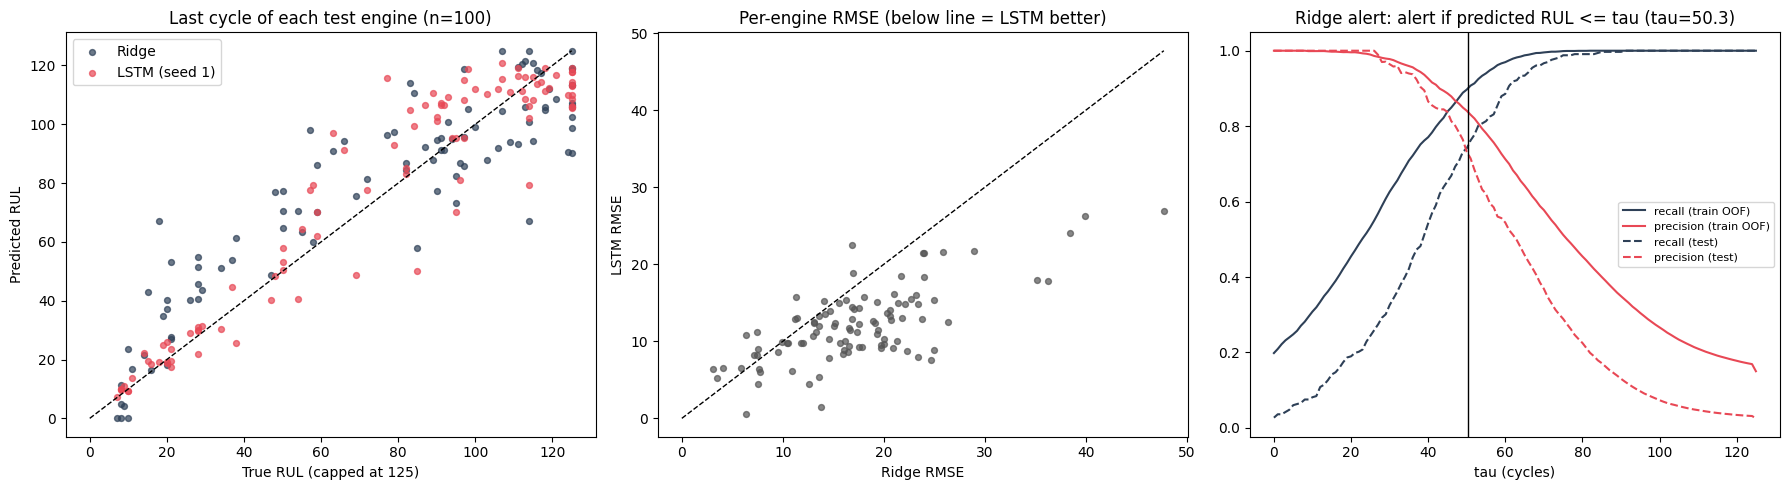

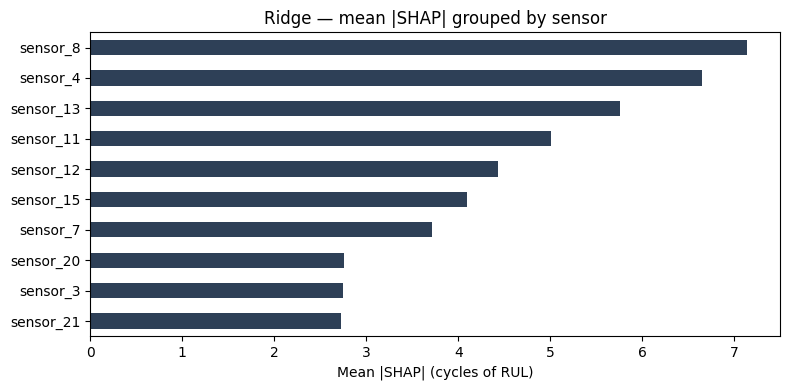


DECISION
  RUL estimate: LSTM (lower error on every regression metric; gap holds per engine)
  Ridge: interpretable baseline (SHAP above)
  Champion LSTM seed for registration: 1 (lowest VALIDATION RMSE, not test)


In [0]:
# ============================================================
# CELL 8 — Final Evaluation: aligned comparison, engine-level
#          significance, alert layer, SHAP (grouped), plots
# Ridge and LSTM are compared on the SAME rows: joined on
# (unit_id, time_cycles), never by row position.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def mean_sd(vals):
    return f"{np.mean(vals):.2f} ± {np.std(vals, ddof=1):.2f}"

# ---------- 1. Aligned comparison + significance, per seed ----------
cmp_rows = []
for seed, run in lstm_runs.items():
    cmp_df = align_predictions(test_df, run["preds"], "lstm_pred").dropna(subset=["lstm_pred"])
    c = compare_models(cmp_df, "RUL_capped", "ridge_pred", "lstm_pred", seed=seed)
    cmp_rows.append({
        "seed": seed,
        "aligned_rows": len(cmp_df),
        "ridge_rmse": rmse(cmp_df["RUL_capped"], cmp_df["ridge_pred"]),
        "lstm_rmse": rmse(cmp_df["RUL_capped"], cmp_df["lstm_pred"]),
        "lstm_better_engines": c["n_engines"] - c["a_better_on_n_engines"],
        "wilcoxon_p_per_engine": c["wilcoxon_per_engine_rmse_p"],
        "wilcoxon_p_last_cycle": c["wilcoxon_last_cycle_abs_err_p"],
        "rmse_gap_ridge_minus_lstm": c["pooled_rmse_diff"],
        "gap_ci95_low": c["pooled_rmse_diff_ci95"][0],
        "gap_ci95_high": c["pooled_rmse_diff_ci95"][1],
    })
cmp_table = pd.DataFrame(cmp_rows)
ridge_aligned_mae = float(np.mean(np.abs(cmp_df["RUL_capped"] - cmp_df["ridge_pred"])))

print("=" * 70)
print("RIDGE vs LSTM — ALIGNED test rows (>= 30 cycles of history), engine = unit")
print(cmp_table.round(4).to_string(index=False))

# ---------- 2. Dedicated alert classifier (optional comparison) ----------
make_clf = lambda: make_pipeline(StandardScaler(),
                                 LogisticRegression(class_weight="balanced", max_iter=5000))
y_lab = (y_train <= ALERT_HORIZON).astype(int)
oof_p = oof_predict(make_clf, X_train, y_lab, groups, clip=None, method="predict_proba")
TAU_CLF = choose_threshold(y_train, oof_p, recall_target=RECALL_TARGET, higher_is_alert=True)["tau"]
clf = make_clf().fit(X_train, y_lab)
test_df["clf_p"] = clf.predict_proba(X_test)[:, 1]
clf_rows = alert_counts(test_df["RUL"], test_df["clf_p"], TAU_CLF, higher_is_alert=True)
clf_eng = engine_level_alerts(test_df, "clf_p", TAU_CLF, higher_is_alert=True)
test_lab = (test_df["RUL"] <= ALERT_HORIZON).astype(int)
ap_ridge = average_precision_score(test_lab, -test_df["ridge_pred"])
ap_clf = average_precision_score(test_lab, test_df["clf_p"])

# ---------- 3. Final results table (README numbers) ----------
r = list(lstm_runs.values())
results = pd.DataFrame({
    "Ridge": [
        f"{ridge_std['last_cycle_rmse_vs_capped_truth']:.2f}",
        f"{ridge_std['last_cycle_rmse_vs_raw_truth']:.2f}",
        f"{ridge_std['last_cycle_mae_vs_capped_truth']:.2f}",
        f"{ridge_std['phm08_score_vs_raw_truth']:.0f}",
        f"{cmp_table.ridge_rmse.iloc[0]:.2f}",
        f"{ridge_aligned_mae:.2f}",
        f"{train_rmse:.2f}",
        f"{TAU_RIDGE:.1f}",
        f"{ridge_rows['recall']:.3f} ({ridge_rows['tp']}/{ridge_rows['tp']+ridge_rows['fn']})",
        f"{ridge_rows['precision']:.3f}",
        f"{ridge_rows['f1']:.3f}",
        f"{ridge_eng['tp']}/25, {ridge_eng['fp']} FA",
    ],
    "LSTM (mean ± sd, 3 seeds)": [
        mean_sd([x["std"]["last_cycle_rmse_vs_capped_truth"] for x in r]),
        mean_sd([x["std"]["last_cycle_rmse_vs_raw_truth"] for x in r]),
        mean_sd([x["std"]["last_cycle_mae_vs_capped_truth"] for x in r]),
        mean_sd([x["std"]["phm08_score_vs_raw_truth"] for x in r]),
        mean_sd([x["aligned_rmse"] for x in r]),
        mean_sd([x["aligned_mae"] for x in r]),
        mean_sd([x["train_rmse"] for x in r]),
        str([round(x["tau"], 1) for x in r]),
        mean_sd([x["rows"]["recall"] for x in r]),
        mean_sd([x["rows"]["precision"] for x in r]),
        mean_sd([x["rows"]["f1"] for x in r]),
        str([f"{x['eng']['tp']}/25, {x['eng']['fp']} FA" for x in r]),
    ],
    "Logistic classifier": [
        "—", "—", "—", "—", "—", "—", "—",
        f"p >= {TAU_CLF:.2f}",
        f"{clf_rows['recall']:.3f} ({clf_rows['tp']}/{clf_rows['tp']+clf_rows['fn']})",
        f"{clf_rows['precision']:.3f}",
        f"{clf_rows['f1']:.3f}",
        f"{clf_eng['tp']}/25, {clf_eng['fp']} FA",
    ],
}, index=[
    "Last-cycle RMSE, capped truth (n=100)",
    "Last-cycle RMSE, raw truth",
    "Last-cycle MAE, capped truth",
    "PHM08 score (raw truth)",
    "RMSE, aligned rows",
    "MAE, aligned rows",
    "Train RMSE",
    "Alert threshold",
    "Alert row recall",
    "Alert row precision",
    "Alert row F1",
    "Engines alerted at last cycle",
])
print("\n" + "=" * 70)
print("FINAL RESULTS — NASA CMAPSS FD001 test set")
print(results.to_string())
print(f"\nAverage precision (threshold-free): Ridge {ap_ridge:.3f} | Logistic {ap_clf:.3f}")

# ---------- 4. Why test recall < the 90% target: positive mix by RUL bucket ----------
def bucket_mix(rul):
    b = pd.cut(rul[rul <= ALERT_HORIZON], [-1, 10, 20, 30], labels=["0-10", "11-20", "21-30"])
    return b.value_counts(normalize=True).sort_index().round(2)
print("\nShare of alert-positive rows by true RUL — train vs test")
print(pd.DataFrame({"train": bucket_mix(y_train), "test": bucket_mix(test_df["RUL"])}).to_string())

# ---------- 5. SHAP for Ridge, grouped by sensor ----------
# For a linear model with independent features, SHAP_j = coef_j * (z_j - mean_train(z_j)).
# The pipeline standardizes on train, so mean_train(z) = 0 and SHAP_j = coef_j * z_j.
scaler, ridge_reg = ridge_model_obj[0], ridge_model_obj[1]
phi = pd.DataFrame(scaler.transform(X_test) * ridge_reg.coef_, columns=feature_cols)
by_sensor = (phi.T.groupby(lambda f: "sensor_" + f.split("_")[1]).sum().T
               .abs().mean().sort_values(ascending=False))
by_family = {fam: phi[[c for c in feature_cols if c.endswith(fam)]].abs().mean().sum()
             for fam in ["_norm", "_roll_mean", "_roll_std"]}
tot = sum(by_family.values())
print("\nRidge SHAP — mean |SHAP| grouped by sensor (top 6):")
print(by_sensor.head(6).round(2).to_string())
print("Share by feature family:", {k: f"{v / tot:.0%}" for k, v in by_family.items()})
print("Note: sensor_8_roll_mean vs sensor_13_roll_mean correlation =",
      round(train_df["sensor_8_roll_mean"].corr(train_df["sensor_13_roll_mean"]), 3),
      "-> report importance by sensor, not by individual column")

# ---------- 6. Plots ----------
best_seed = min(lstm_runs, key=lambda s: lstm_runs[s]["hist"]["best_val_rmse"])  # chosen on VALIDATION
plot_df = align_predictions(test_df, lstm_runs[best_seed]["preds"], "lstm_pred").dropna(subset=["lstm_pred"])
last = last_cycle(plot_df)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# (a) last-cycle predicted vs true
for col, name, color in [("ridge_pred", "Ridge", "#2E4057"), ("lstm_pred", f"LSTM (seed {best_seed})", "#E84855")]:
    axes[0].scatter(np.minimum(last["RUL"], 125), last[col], s=18, alpha=0.7, label=name, color=color)
axes[0].plot([0, 125], [0, 125], "k--", lw=1)
axes[0].set(title="Last cycle of each test engine (n=100)", xlabel="True RUL (capped at 125)", ylabel="Predicted RUL")
axes[0].legend()
# (b) per-engine RMSE, Ridge vs LSTM
pe = per_engine_errors(plot_df, "RUL_capped", "ridge_pred", "lstm_pred")
axes[1].scatter(pe.rmse_a, pe.rmse_b, s=18, alpha=0.7, color="#555")
m = max(pe.rmse_a.max(), pe.rmse_b.max())
axes[1].plot([0, m], [0, m], "k--", lw=1)
axes[1].set(title="Per-engine RMSE (below line = LSTM better)", xlabel="Ridge RMSE", ylabel="LSTM RMSE")
# (c) Ridge alert threshold curve: train OOF vs test
for yt, sc, name, ls in [(y_train, oof_ridge, "train OOF", "-"), (test_df["RUL"], test_df["ridge_pred"], "test", "--")]:
    cv = threshold_curve(yt, sc, taus=np.arange(0, 126))
    axes[2].plot(cv.tau, cv.recall, ls, color="#2E4057", label=f"recall ({name})")
    axes[2].plot(cv.tau, cv.precision, ls, color="#E84855", label=f"precision ({name})")
axes[2].axvline(TAU_RIDGE, color="k", lw=1)
axes[2].set(title=f"Ridge alert: alert if predicted RUL <= tau (tau={TAU_RIDGE:.1f})", xlabel="tau (cycles)")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
by_sensor.head(10)[::-1].plot.barh(ax=ax, color="#2E4057")
ax.set(title="Ridge — mean |SHAP| grouped by sensor", xlabel="Mean |SHAP| (cycles of RUL)")
plt.tight_layout()
plt.show()

print("\n" + "=" * 70)
print("DECISION")
print("  RUL estimate: LSTM (lower error on every regression metric; gap holds per engine)")
print("  Ridge: interpretable baseline (SHAP above)")
print(f"  Champion LSTM seed for registration: {best_seed} (lowest VALIDATION RMSE, not test)")